<a href="https://colab.research.google.com/github/HoJin26/Linear-Algebra/blob/main/rilakkuma_transform.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 변환을 이용한 리락쿠마 그리기

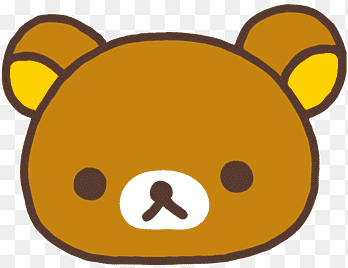

### 라이브러리 선언

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.patches import Circle

INF = 180  # 그림판 크기
LEN = 100

BROWN = '#5B392A'       # 갈색
BEAR_BROWN = '#C98513'  # 얼굴, 귀 색
EAR_YELLOW = '#FFD500'  # 귀 안쪽 색


### 축 그리기


In [ ]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.18, zorder=0)  # x축
  ax.axvline(0, color='black', alpha=0.18, zorder=0)  # y축
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')


### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)
* scale(p, sx, sy)
* shear_x(p, sx)
* shear_y(p, sy)
* reflect_x(p)
* reflect_y(p)
* reflect_origin(p)
* reflect_yx(p)

### 이동

In [ ]:
def translate(p, dx, dy):
  # 1. 동차좌표계로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 만들기
  m = np.array([[1.0, 0.0, dx],
                [0.0, 1.0, dy],
                [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표로 되돌리기
  return np.array([q[0], q[1]])


### 회전

In [ ]:
def rotate(p, theta):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[np.cos(theta), -np.sin(theta), 0.0],
                [np.sin(theta),  np.cos(theta), 0.0],
                [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])


### 크기

In [ ]:
def scale(p, sx, sy):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[sx,  0.0, 0.0],
                [0.0, sy,  0.0],
                [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])


### 기울기

In [ ]:
def shear_x(p, sx):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[1.0, sx,  0.0],
                [0.0, 1.0, 0.0],
                [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])


def shear_y(p, sy):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[1.0, 0.0, 0.0],
                [sy,  1.0, 0.0],
                [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])


### 반전

In [ ]:
# x축 대칭
def reflect_x(p):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[1.0,  0.0, 0.0],
                [0.0, -1.0, 0.0],
                [0.0,  0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

# y축 대칭
def reflect_y(p):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[-1.0, 0.0, 0.0],
                [ 0.0, 1.0, 0.0],
                [ 0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

# 원점 대칭
def reflect_origin(p):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[-1.0,  0.0, 0.0],
                [ 0.0, -1.0, 0.0],
                [ 0.0,  0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

# y=x 대칭
def reflect_yx(p):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[0.0, 1.0, 0.0],
                [1.0, 0.0, 0.0],
                [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])


### 도형 그리기 함수


In [ ]:
def draw_rectangle(ax, p1, p2, p3, p4, facecolor='none', edgecolor=BROWN, linewidth=2, zorder=1):
  my_polygon = Polygon(
      [p1, p2, p3, p4],
      closed=True,
      facecolor=facecolor,
      edgecolor=edgecolor,
      linewidth=linewidth,
      zorder=zorder
  )
  ax.add_patch(my_polygon)


def draw_circle(ax, center, radius, facecolor, edgecolor=BROWN, linewidth=2, zorder=1):
  my_circle = Circle(
      center,
      radius,
      facecolor=facecolor,
      edgecolor=edgecolor,
      linewidth=linewidth,
      zorder=zorder
  )
  ax.add_patch(my_circle)


### 2. 파트 그리기
* draw_ears(ax)       # 왼쪽 귀를 그리고 y축 대칭으로 오른쪽 귀 만들기
* draw_face(ax)       # 얼굴
* draw_muzzle(ax)     # 입 주변
* draw_eyes(ax)       # 왼쪽 눈을 그리고 y축 대칭으로 오른쪽 눈 만들기
* draw_mouth(ax)      #  입

### 귀 파트

In [ ]:
def draw_ears(ax):
  # 왼쪽 귀 테두리를 원으로 그리고 y축 대칭으로 오른쪽 귀 그리기
  center = np.array([0, 0])
  left_center = translate(center, -110, 95)
  right_center = reflect_y(left_center)

  draw_circle(ax, left_center, 48, BEAR_BROWN, BROWN, linewidth=5, zorder=1)
  draw_circle(ax, right_center, 48, BEAR_BROWN, BROWN, linewidth=5, zorder=1)

  # 귀 안쪽도 왼쪽을 그리고 y축 대칭
  left_inner = translate(center, -110, 95)
  right_inner = reflect_y(left_inner)
  draw_circle(ax, left_inner, 34, EAR_YELLOW, BROWN, linewidth=2, zorder=2)
  draw_circle(ax, right_inner, 34, EAR_YELLOW, BROWN, linewidth=2, zorder=2)


### 얼굴 파트

In [ ]:
def draw_face(ax):
  # 얼굴 테두리
  center = np.array([0, 0])
  center = translate(center, 0, -15)
  draw_circle(ax, center, 135, BEAR_BROWN, BROWN, linewidth=6, zorder=3)


### 입 주변 파트

In [ ]:
def draw_muzzle(ax):
  # 흰 부분을 원 세 개
  left_center = np.array([-17, -44])
  middle_center = np.array([0, -44])
  right_center = np.array([17, -44])

  draw_circle(ax, left_center, 27, 'white', 'white', linewidth=0, zorder=4)
  draw_circle(ax, right_center, 27, 'white', 'white', linewidth=0, zorder=4)
  draw_circle(ax, middle_center, 34, 'white', 'white', linewidth=0, zorder=4)


### 눈

In [ ]:
def draw_eyes(ax):
  left_eye = np.array([-65, 0])
  right_eye = reflect_y(left_eye)

  draw_circle(ax, left_eye, 10, BROWN, BROWN, linewidth=1, zorder=5)
  draw_circle(ax, right_eye, 10, BROWN, BROWN, linewidth=1, zorder=5)


### 입

In [ ]:
def draw_mouth(ax):
  # --- 1. 가운데 세로 직사각형 ---
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  q1 = scale(q1, 0.07, 0.18)
  q2 = scale(q2, 0.07, 0.18)
  q3 = scale(q3, 0.07, 0.18)
  q4 = scale(q4, 0.07, 0.18)

  q1 = translate(q1, 0, -47)
  q2 = translate(q2, 0, -47)
  q3 = translate(q3, 0, -47)
  q4 = translate(q4, 0, -47)

  draw_rectangle(ax, q1, q2, q3, q4, facecolor=BROWN, edgecolor=BROWN, linewidth=1, zorder=5)

  # --- 2. 왼쪽 아래 직사각형 ---
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)


  q1 = scale(q1, 0.19, 0.055)
  q2 = scale(q2, 0.19, 0.055)
  q3 = scale(q3, 0.19, 0.055)
  q4 = scale(q4, 0.19, 0.055)

  q1 = rotate(q1, np.pi/4)
  q2 = rotate(q2, np.pi/4)
  q3 = rotate(q3, np.pi/4)
  q4 = rotate(q4, np.pi/4)

  q1 = translate(q1, -5, -56)
  q2 = translate(q2, -5, -56)
  q3 = translate(q3, -5, -56)
  q4 = translate(q4, -5, -56)

  draw_rectangle(ax, q1, q2, q3, q4, facecolor=BROWN, edgecolor=BROWN, linewidth=1, zorder=5)

  # --- 3. y축 대칭으로 오른쪽 입 그리기 ---
  r1 = reflect_y(q1)
  r2 = reflect_y(q2)
  r3 = reflect_y(q3)
  r4 = reflect_y(q4)

  draw_rectangle(ax, r1, r2, r3, r4, facecolor=BROWN, edgecolor=BROWN, linewidth=1, zorder=5)

  # 코
  nose = np.array([0, -30])
  draw_circle(ax, nose, 9, BROWN, BROWN, linewidth=1, zorder=6)


### 3. 리락쿠마 그리기

In [ ]:
def draw_rilakkuma(ax):
  # 뒤쪽 부터 순서대로 그리기
  draw_ears(ax)
  draw_face(ax)
  draw_muzzle(ax)
  draw_eyes(ax)
  draw_mouth(ax)


### 4. main

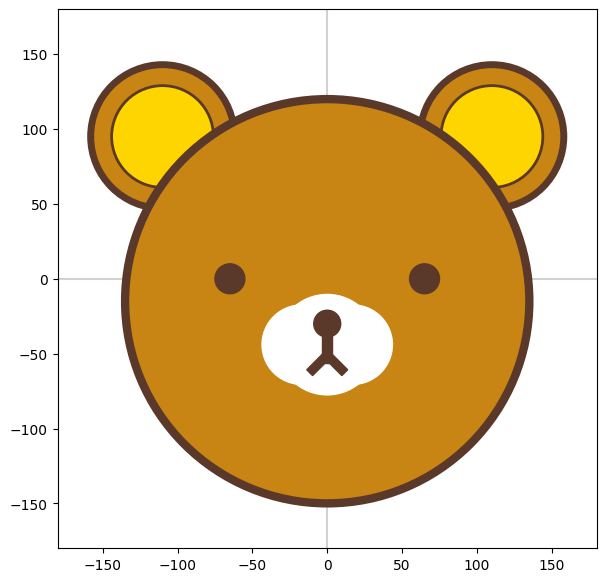

In [ ]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7, 7))

# 축 그리기
draw_axis(ax)

# 리락쿠마 그리기
draw_rilakkuma(ax)

plt.show()
